<a href="https://colab.research.google.com/github/ibrahimsaqib-ai/Introduction-to-AI-Labs/blob/main/Lab-07/Digit_Recognition_on_MNIST_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Import Libraries and Load MNIST Dataset
We will import the necessary libraries, load the MNIST dataset using Keras, and preprocess the test data so it matches the input format expected by the Convolutional Neural Network (CNN).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

# Load MNIST data
(_, _), (x_test, y_test) = keras.datasets.mnist.load_data()

# Preprocess the data
# Scale images to the [0, 1] range
x_test_scaled = x_test.astype("float32") / 255.0

# Make sure images have shape (28, 28, 1)
x_test_scaled = np.expand_dims(x_test_scaled, -1)

print("Test data shape:", x_test_scaled.shape)
print("Test labels shape:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Test data shape: (10000, 28, 28, 1)
Test labels shape: (10000,)


### 2. Load the Pretrained CNN Model
We will load the model from `/content/mnist_cnn_model.keras` and display its architecture summary.

In [9]:
import os
import json
import zipfile
import shutil
import tensorflow as tf
from tensorflow import keras

model_path = '/content/mnist_cnn_model.keras'
pitched_model_path = '/content/mnist_cnn_model_patched.keras'

def patch_keras_model(src, dst):
    """Extract .keras zip, programmatically clean dictionary keys from configs, and re-zip."""
    temp_dir = '/content/temp_keras_model'
    if os.path.exists(temp_dir):
        shutil.rmtree(temp_dir)

    # Unzip
    with zipfile.ZipFile(src, 'r') as zip_ref:
        zip_ref.extractall(temp_dir)

    # Clean config file(s)
    config_filepaths = [
        os.path.join(temp_dir, 'config.json'),
        os.path.join(temp_dir, 'model.ndarray_aliases.json')
    ]

    # Helper to recursively delete specific keys
    def purge_keys(d):
        if isinstance(d, dict):
            d.pop('input_axes', None)
            d.pop('output_axes', None)
            for k, v in list(d.items()):
                purge_keys(v)
        elif isinstance(d, list):
            for item in d:
                purge_keys(item)

    for filepath in config_filepaths:
        if os.path.exists(filepath):
            with open(filepath, 'r') as f:
                data = json.load(f)

            # Clean dictionary structure
            purge_keys(data)

            with open(filepath, 'w') as f:
                json.dump(data, f)

    # Re-zip
    with zipfile.ZipFile(dst, 'w', zipfile.ZIP_DEFLATED) as zip_out:
        for root, dirs, files in os.walk(temp_dir):
            for file in files:
                abs_path = os.path.join(root, file)
                rel_path = os.path.relpath(abs_path, temp_dir)
                zip_out.write(abs_path, rel_path)

    shutil.rmtree(temp_dir)
    print("Patched Keras archive successfully created with valid JSON.")

try:
    patch_keras_model(model_path, pitched_model_path)
    model = keras.models.load_model(pitched_model_path, compile=False)
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    print("Patched model loaded and compiled successfully!")
    model.summary()
except Exception as e:
    print(f"Failed to load patched model: {e}")

Patched Keras archive successfully created with valid JSON.
Patched model loaded and compiled successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

### 3. Evaluate the Model and Make Predictions
Now we evaluate the loaded model on the test dataset and visualize some predictions alongside their true labels.

Test Loss: 0.0178
Test Accuracy: 0.9948
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step


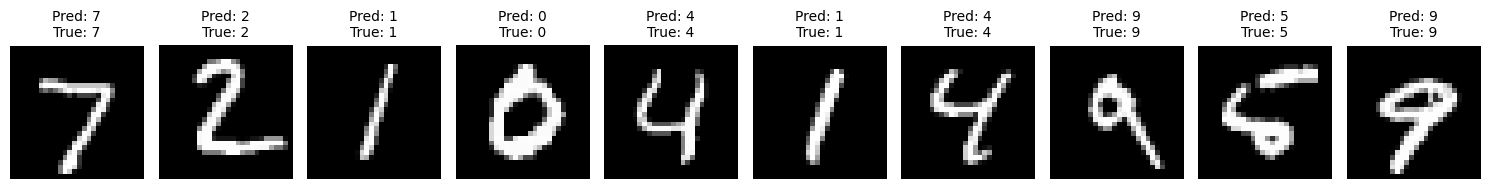

In [10]:
# Evaluate the model on test data
loss, accuracy = model.evaluate(x_test_scaled, y_test, verbose=0)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

# Make predictions
predictions = model.predict(x_test_scaled[:10])
predicted_labels = np.argmax(predictions, axis=1)

# Plot the first 10 test images and their predicted labels
plt.figure(figsize=(15, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Pred: {predicted_labels[i]}\nTrue: {y_test[i]}", fontsize=10)
    plt.axis('off')
plt.tight_layout()
plt.show()

Generating predictions for the entire test set...
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step


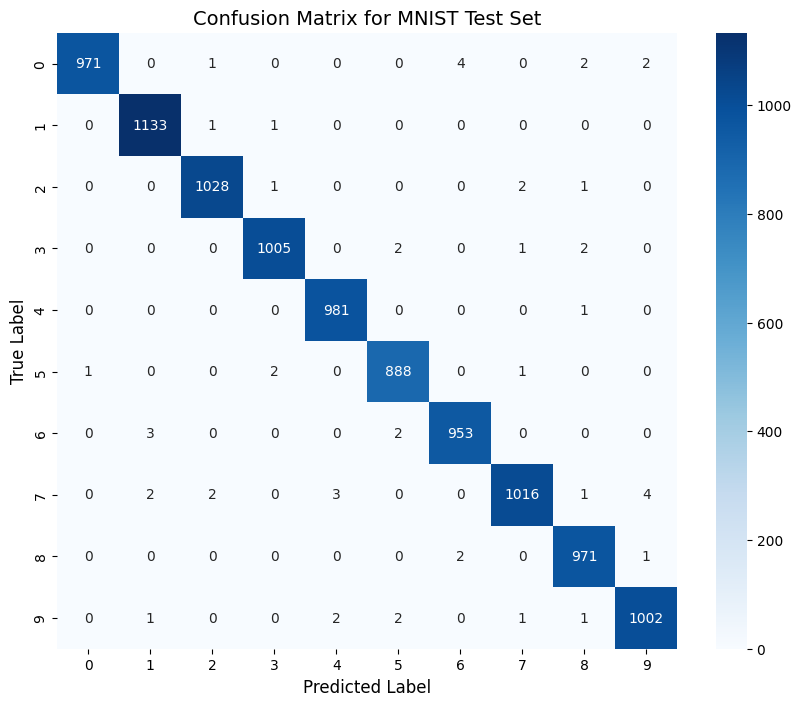

In [11]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Get predictions for the entire test set
print("Generating predictions for the entire test set...")
all_predictions = model.predict(x_test_scaled, verbose=1)
all_predicted_labels = np.argmax(all_predictions, axis=1)

# 2. Calculate the confusion matrix
cm = confusion_matrix(y_test, all_predicted_labels)

# 3. Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=list(range(10)),
            yticklabels=list(range(10)))
plt.title('Confusion Matrix for MNIST Test Set', fontsize=14)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.show()

Apni handwritten digit (0-9) ki image upload karein:


Saving images.png to images.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


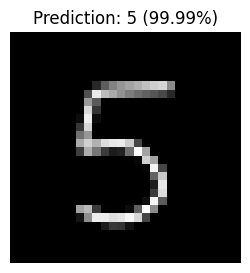

In [12]:
from google.colab import files
from PIL import Image
import io

print("Apni handwritten digit (0-9) ki image upload karein:")
uploaded = files.upload()

for file_name in uploaded.keys():
    # Image load karein
    img = Image.open(io.BytesIO(uploaded[file_name]))

    # Image ko Grayscale (L) mein convert karein aur 28x28 size ka karein
    img_gray = img.convert('L').resize((28, 28))

    # Image ko numpy array mein convert karein
    img_np = np.array(img_gray)

    # MNIST mein background black aur digit white hota hai.
    # Agar aapki image ka background white aur text black hai, to colors ko invert karna hoga.
    # Hum check karte hain: agar corner pixels white hain, to hum image ko invert kar dete hain.
    if img_np[0, 0] > 127:
        img_np = 255 - img_np

    # Data ko scale karein (0 to 1 range)
    img_scaled = img_np.astype('float32') / 255.0

    # Model ke input format (1, 28, 28, 1) ke mutabiq reshape karein
    img_input = np.expand_dims(img_scaled, axis=(0, -1))

    # Prediction karein
    pred = model.predict(img_input)
    predicted_digit = np.argmax(pred)
    confidence = np.max(pred) * 100

    # Result display karein
    plt.figure(figsize=(3, 3))
    plt.imshow(img_np, cmap='gray')
    plt.title(f"Prediction: {predicted_digit} ({confidence:.2f}%)")
    plt.axis('off')
    plt.show()